# Phân Tích Khám Phá Dữ Liệu Giao Thông TP. Hồ Chí Minh (HCMC Traffic Flow EDA)
**Đồ án Cuối kỳ:** Trực quan hóa Dữ liệu (Data Visualization)  
**Môi trường thực thi:** Python Virtual Environment (`.venv`)

---

## Giới thiệu Tổng quan về Bộ Dữ liệu

Notebook này thực hiện toàn diện quy trình kiểm tra chất lượng dữ liệu, tiền xử lý, trích xuất đặc trưng và phân tích khám phá (EDA) trên bộ dữ liệu **"Traffic Flow data in Ho Chi Minh City, Viet Nam"**.
* **Đơn vị thu thập gốc:** Nhóm nghiên cứu thuộc **Trường Đại học Bách Khoa – ĐHQG-HCM (Ho Chi Minh City University of Technology - HCMUT)**.
* **Tác giả chia sẻ công khai:** **Thanh Nguyen** (`thanhnguyen2612`) trên nền tảng Kaggle ([Xem liên kết Kaggle](https://www.kaggle.com/datasets/thanhnguyen2612/traffic-flow-data-in-ho-chi-minh-city-viet-nam)).
* **Phạm vi không gian:** Mạng lưới giao thông đường bộ tại TP. Hồ Chí Minh (tọa độ trải dài từ 10.67°N đến 10.89°N, 106.54°E đến 106.87°E).
* **Phạm vi thời gian:** Từ tháng 07/2020 đến tháng 04/2021.

### Cấu trúc 5 Tệp Dữ liệu trong Thư mục `data/`:
1. `nodes.csv` (577.967 dòng): Tọa độ địa lý (`long`, `lat`) của các điểm nút / giao lộ trên bản đồ OpenStreetMap.
2. `streets.csv` (5.553 dòng): Thuộc tính các tuyến đường (tên đường, cấp đường `level`, loại đường `type`, vận tốc tối đa `max_velocity`).
3. `segments.csv` (84.633 dòng): Các đoạn đường vật lý nối giữa hai nút (`s_node_id` và `e_node_id`), chiều dài (`length`), thuộc tuyến đường nào (`street_id`).
4. `segment_status.csv` (90.938 dòng): Lịch sử đo vận tốc thực tế (`velocity`) theo mốc thời gian (`updated_at`) tại các phân đoạn.
5. `train.csv` (33.441 dòng): Bảng dữ liệu chính phục vụ bài toán dự báo, tích hợp không gian và thời gian kèm nhãn mức độ phục vụ giao thông (**Level of Service - LOS** từ A đến F).

## 1. Thiết Lập Môi Trường & Cấu Hình Trực Quan Hóa (Libraries & Styling)

Cấu hình giao diện biểu đồ với Seaborn và Matplotlib, thiết lập bảng màu nhất quán phản ánh bản chất của từng biến phân loại:
* **`LOS_COLORS`**: Thang màu từ xanh lá (**A** - thông suốt) qua vàng, cam đến đỏ sẫm (**F** - kẹt xe nghiêm trọng).
* **`WEEKDAY_ORDER`**: Thứ tự từ Thứ Hai đến Chủ Nhật.
* **Tự động nhận diện đường dẫn `DATA_DIR`**: Hoạt động linh hoạt từ thư mục gốc hoặc thư mục `source/`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

# Cấu hình giao diện biểu đồ nhất quán
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelweight": "semibold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
})

# Thang màu chuẩn hóa theo nghiệp vụ giao thông (Highway Capacity Manual)
LOS_ORDER = ["A", "B", "C", "D", "E", "F"]
LOS_COLORS = {
    "A": "#2ca02c",  # Xanh lá đậm - Lưu thông tự do (Free Flow)
    "B": "#74c476",  # Xanh non - Lưu thông tương đối tự do (Reasonably Free Flow)
    "C": "#fed976",  # Vàng chanh - Dòng phương tiện ổn định (Stable Flow)
    "D": "#feb24c",  # Vàng cam - Tiếp cận ngưỡng bất ổn định (Approaching Unstable)
    "E": "#f03b20",  # Cam đỏ - Bất ổn định, sát công suất (Unstable Flow)
    "F": "#bd0026",  # Đỏ thẫm - Kẹt cứng, dòng dừng hoàn toàn (Breakdown / Forced Flow)
}

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
WEEKDAY_VN = ["Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm", "Thứ Sáu", "Thứ Bảy", "Chủ Nhật"]
WEEKDAY_MAP = dict(zip(range(7), WEEKDAY_VN))

# Tự động tìm đường dẫn chứa các tệp dữ liệu csv
def get_data_dir():
    candidates = [
        Path("final_lab/data"),
        Path("../data"),
        Path("data"),
    ]
    for c in candidates:
        if (c / "train.csv").exists():
            return c
    raise FileNotFoundError("Không tìm thấy thư mục chứa tệp train.csv!")

DATA_DIR = get_data_dir()
print(f"Data Directory: {DATA_DIR.resolve()}")

Data Directory: /home/dekii2275/Data-Visualization/final_lab/data


## 2. Nạp Dữ Liệu & Kiểm Tra Tính Toàn Vẹn (Data Ingestion & Integrity Check)

Trong phần này, ta nạp toàn bộ 5 tệp dữ liệu vào bộ nhớ và tiến hành đánh giá:
* Kích thước ma trận (dòng × cột).
* Dung lượng bộ nhớ RAM tiêu thụ.
* Số lượng và tỷ lệ giá trị còn khuyết (Missing values / Nulls).
* Kiểm tra các dòng dữ liệu bị trùng lặp hoàn toàn (Duplicate rows).

In [2]:
# Nạp các tệp dữ liệu
train_df = pd.read_csv(DATA_DIR / "train.csv")
segments_df = pd.read_csv(DATA_DIR / "segments.csv")
streets_df = pd.read_csv(DATA_DIR / "streets.csv")
seg_status_df = pd.read_csv(DATA_DIR / "segment_status.csv")
nodes_df = pd.read_csv(DATA_DIR / "nodes.csv")

dfs = {
    "train.csv": train_df,
    "segments.csv": segments_df,
    "streets.csv": streets_df,
    "segment_status.csv": seg_status_df,
    "nodes.csv": nodes_df,
}

# Tổng hợp kiểm tra tính toàn vẹn
integrity_summary = []
for name, df in dfs.items():
    mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    null_cols = df.isnull().sum()[df.isnull().sum() > 0]
    null_info = ", ".join([f"{col}: {cnt} ({cnt/len(df)*100:.1f}%)" for col, cnt in null_cols.items()])
    integrity_summary.append({
        "Dataset": name,
        "Số dòng": f"{len(df):,}",
        "Số cột": df.shape[1],
        "Bộ nhớ (MB)": f"{mem_mb:.2f}",
        "Số dòng trùng lặp": f"{df.duplicated().sum():,}",
        "Cột khuyết dữ liệu": null_info if null_info else "Không có",
    })

integrity_table = pd.DataFrame(integrity_summary)
display(integrity_table)

,Dataset,Số dòng,Số cột,Bộ nhớ (MB),Số dòng trùng lặp,Cột khuyết dữ liệu
0,train.csv,"33,441",18,13.38,0,"max_velocity: 28495 (85.2%), street_name: 1 (0..."
1,segments.csv,"84,633",11,28.25,0,"max_velocity: 74762 (88.3%), street_name: 152 ..."
2,streets.csv,"5,553",5,0.82,0,"max_velocity: 4566 (82.2%), name: 1605 (28.9%)"
3,segment_status.csv,"90,938",4,8.41,0,Không có
4,nodes.csv,"577,967",3,13.23,0,Không có


In [3]:
print("=== Xem trước mẫu dữ liệu train.csv (3 dòng đầu) ===")
display(train_df.head(3))

print("=== Thống kê mô tả các thuộc tính số của train.csv ===")
display(train_df[["length", "street_level", "max_velocity", "lat_snode", "long_snode"]].describe().T)

=== Xem trước mẫu dữ liệu train.csv (3 dòng đầu) ===


,_id,segment_id,date,weekday,period,LOS,s_node_id,e_node_id,length,street_id,max_velocity,street_level,street_name,street_type,long_snode,lat_snode,long_enode,lat_enode
0,0,26,2021-04-16,4,period_0_30,A,366428456,366416066,116,32575820,NaN,4,Nguyễn Văn Bá,tertiary,106.768732,10.841506,106.769254,10.842422
1,1,33,2020-08-02,6,period_23_30,C,366469460,3792257828,26,32575862,NaN,3,Đường số 5,secondary,106.761957,10.878650,106.762143,10.878808
2,2,33,2020-08-03,0,period_0_00,D,366469460,3792257828,26,32575862,NaN,3,Đường số 5,secondary,106.761957,10.878650,106.762143,10.878808


=== Thống kê mô tả các thuộc tính số của train.csv ===


,count,mean,std,min,25%,50%,75%,max
length,33441.0,48.709010,52.251062,0.000000,17.000000,34.000000,63.000000,1011.000000
street_level,33441.0,3.029993,1.022137,1.000000,2.000000,3.000000,4.000000,4.000000
max_velocity,4946.0,59.299434,14.172472,10.000000,50.000000,60.000000,60.000000,120.000000
lat_snode,33441.0,10.804326,0.040358,10.676452,10.772135,10.797884,10.837117,10.888965
long_snode,33441.0,106.670354,0.041887,106.537476,106.649521,106.664687,106.685096,106.867740


## 3. Tiền Xử Lý & Kỹ Thuật Tạo Đặc Trưng (Preprocessing & Feature Engineering)

Để phục vụ phân tích chuyên sâu và chuẩn bị cho mô hình hóa:
1. **Chuẩn hóa thời gian:** Chuyển `date` sang kiểu datetime, trích xuất `year`, `month`, `month_name`, `weekday_name`, và cờ `is_weekend` (1 nếu là Thứ Bảy hoặc Chủ Nhật).
2. **Chuyển đổi khung giờ `period`:** Phân tách trường chuỗi `period_H_M` thành giá trị giờ liên tục `hour_float` ($H + M/60$, từ 0.0 đến 23.5) và giờ nguyên `hour_int` ($0 \dots 23$).
3. **Phân loại ca thời gian trong ngày:**
   * **Đêm & Rạng sáng (Early Morning):** 00:00 – 06:00
   * **Cao điểm sáng (Morning Rush):** 06:30 – 09:00
   * **Giữa ngày (Midday):** 09:30 – 16:00
   * **Cao điểm chiều (Evening Rush):** 16:30 – 19:30
   * **Buổi tối (Night):** 20:00 – 23:30
4. **Mã hóa số học cho LOS:** Tạo `LOS_score` với thang từ 1 (A) đến 6 (F) để tính chỉ số ùn tắc trung bình.
5. **Cờ nhị phân ùn tắc nghiêm trọng:** `is_severe_congestion` = 1 khi LOS thuộc nhóm $\{E, F\}$, ngược lại = 0.
6. **Làm sạch phân loại đường:** Gom các nhãn OpenStreetMap cá biệt/POI ít gặp vào nhóm `'other'`.
7. **Phân tích thời gian trên `segment_status.csv`:** Phân tích trường `updated_at` và lọc các giá trị vận tốc bất thường.

In [4]:
# 1. Xử lý thời gian cho train_df
train_df["datetime"] = pd.to_datetime(train_df["date"])
train_df["month"] = train_df["datetime"].dt.month
train_df["month_name"] = train_df["datetime"].dt.strftime("%Y-%m")
train_df["weekday_vn"] = train_df["weekday"].map(WEEKDAY_MAP)
train_df["is_weekend"] = train_df["weekday"].isin([5, 6]).astype(int)

# 2. Xử lý period thành hour liên tục
def parse_period_to_hour(p_str):
    parts = str(p_str).split("_")
    h = int(parts[1])
    m = int(parts[2])
    return h + m / 60.0

train_df["hour_float"] = train_df["period"].apply(parse_period_to_hour)
train_df["hour_int"] = train_df["hour_float"].astype(int)

# 3. Phân nhóm ca thời gian
def categorize_time_of_day(h):
    if h < 6.5:
        return "Đêm/Sáng sớm (0h-6h)"
    elif 6.5 <= h <= 9.0:
        return "Cao điểm sáng (6h30-9h)"
    elif 9.0 < h < 16.5:
        return "Giữa ngày (9h30-16h)"
    elif 16.5 <= h <= 19.5:
        return "Cao điểm chiều (16h30-19h30)"
    else:
        return "Buổi tối (20h-23h30)"

train_df["time_of_day"] = train_df["hour_float"].apply(categorize_time_of_day)

# 4. Mã hóa mức độ ùn tắc
los_score_dict = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6}
train_df["LOS_score"] = train_df["LOS"].map(los_score_dict)
train_df["is_severe_congestion"] = train_df["LOS"].isin(["E", "F"]).astype(int)

# 5. Làm sạch phân loại đường
major_road_types = ["primary", "secondary", "tertiary", "trunk", "unclassified"]
train_df["street_type_clean"] = train_df["street_type"].apply(
    lambda x: x if x in major_road_types else "other"
)

# 6. Xử lý segment_status_df
seg_status_df["datetime"] = pd.to_datetime(seg_status_df["updated_at"])
seg_status_df["hour"] = seg_status_df["datetime"].dt.hour
seg_status_df["weekday"] = seg_status_df["datetime"].dt.dayofweek

print(f"Hoàn thành tiền xử lý train_df! Số lượng bản ghi: {len(train_df):,}")
print(f"Khoảng ngày: {train_df['date'].min()} đến {train_df['date'].max()} ({train_df['date'].nunique()} ngày khác nhau)")
print(f"Số lượng khung giờ period quan sát được: {train_df['period'].nunique()}/48 khung")

Hoàn thành tiền xử lý train_df! Số lượng bản ghi: 33,441
Khoảng ngày: 2020-07-03 đến 2021-04-22 (122 ngày khác nhau)
Số lượng khung giờ period quan sát được: 46/48 khung


## 4. Phân Tích Khám Phá & Trực Quan Hóa Dữ Liệu (EDA)

### 4.0. Thông Tin Cơ Bản Của Dữ Liệu: Quy Mô Dòng Phương Tiện & Phân Cấp Đường Bộ

> **Tổng quan nền tảng về bộ dữ liệu:**  
> *Bộ dữ liệu phản ánh thực trạng lưu thông và vận tốc phương tiện trên mạng lưới đường bộ TP. Hồ Chí Minh trong giai đoạn từ tháng 07/2020 đến tháng 04/2021, được nhóm nghiên cứu Trường ĐH Bách Khoa – ĐHQG-HCM thu thập với quy mô hơn 33.400 mẫu quan sát dòng xe và gần 91.000 bản ghi vận tốc cảm biến tức thời.*  
> *Dữ liệu được tổ chức đa chiều kết hợp giữa đặc trưng không gian (tọa độ GPS nút giao, phân cấp đường, chiều dài của hơn 84.600 đoạn đường vật lý) và chuỗi thời gian thực tế (vận tốc di chuyển, thời điểm cập nhật, cùng nhãn đánh giá mức độ phục vụ giao thông LOS từ A đến F theo chuẩn Highway Capacity Manual).*

Cặp biểu đồ dưới đây được tinh gọn theo nguyên tắc trực quan hóa dữ liệu hiện đại, trả lời 2 câu hỏi cốt lõi:
1. **Bức tranh tổng thể mức phục vụ giao thông (Donut Chart 3 nhóm):** Gom 6 cấp LOS thành 3 trạng thái thực tế: *Thông suốt (A–C chiếm 65,2%)*, *Tiệm cận ùn ứ (D chiếm 11,1%)*, và *Kẹt xe nghiêm trọng (E–F chiếm 23,7%)* giúp người xem nắm bắt ngay quy mô quá tải của mạng lưới.
2. **Tỷ lệ kẹt xe nghiêm trọng theo phân cấp đường (Ranked Bar Chart):** Thay vì biểu đồ cột chồng nhiều màu gây nhiễu, biểu đồ tập trung trực tiếp vào tỷ lệ ùn tắc nghiêm trọng (LOS E–F) đối chiếu với mức trung bình đô thị (23,7%), làm nổi bật nghịch lý hạ tầng: *Đường nhánh và đường nội bộ chịu áp lực kẹt xe cao gấp 2,3 lần so với đường trục chính.*


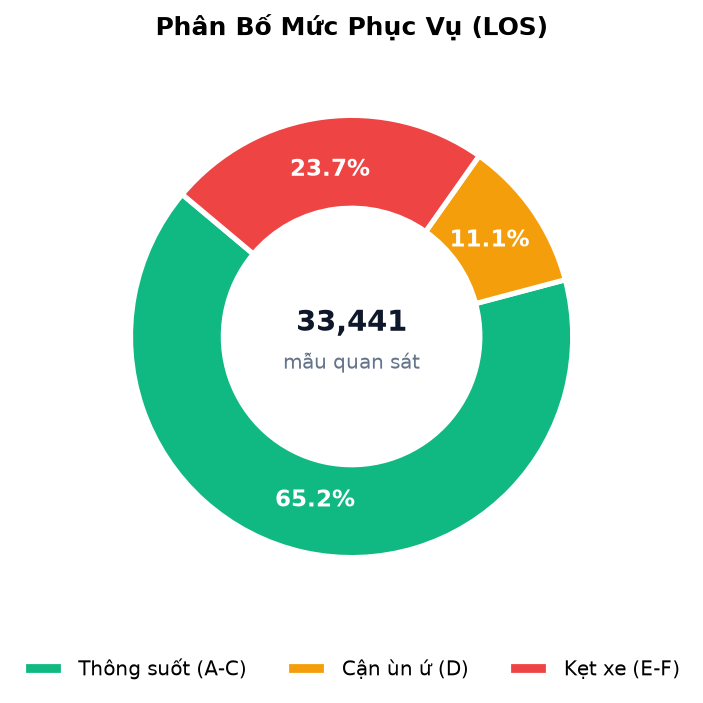

In [9]:
# Biểu đồ 1: Phân bố mức phục vụ giao thông (LOS)
fig, ax = plt.subplots(figsize=(6, 4.8))

c_counts = [
    train_df["LOS"].isin(["A", "B", "C"]).sum(),
    train_df["LOS"].eq("D").sum(),
    train_df["LOS"].isin(["E", "F"]).sum(),
]
total_n = len(train_df)
c_labels = ["Thông suốt (A-C)", "Cận ùn ứ (D)", "Kẹt xe (E-F)"]
c_colors = ["#10b981", "#f59e0b", "#ef4444"]

wedges, texts, autotexts = ax.pie(
    c_counts,
    autopct="%1.1f%%",
    pctdistance=0.76,
    startangle=140,
    colors=c_colors,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2.5),
)
for at in autotexts:
    at.set_color("white")
    at.set_fontweight("bold")
    at.set_fontsize(11)

ax.text(0, 0.06, f"{total_n:,}", ha="center", va="center", fontsize=14, fontweight="bold", color="#0f172a")
ax.text(0, -0.12, "mẫu quan sát", ha="center", va="center", fontsize=9.5, color="#64748b")

ax.legend(
    wedges, c_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    frameon=False,
    fontsize=9.5,
)
ax.set_title("Phân Bố Mức Phục Vụ (LOS)", fontsize=12, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()


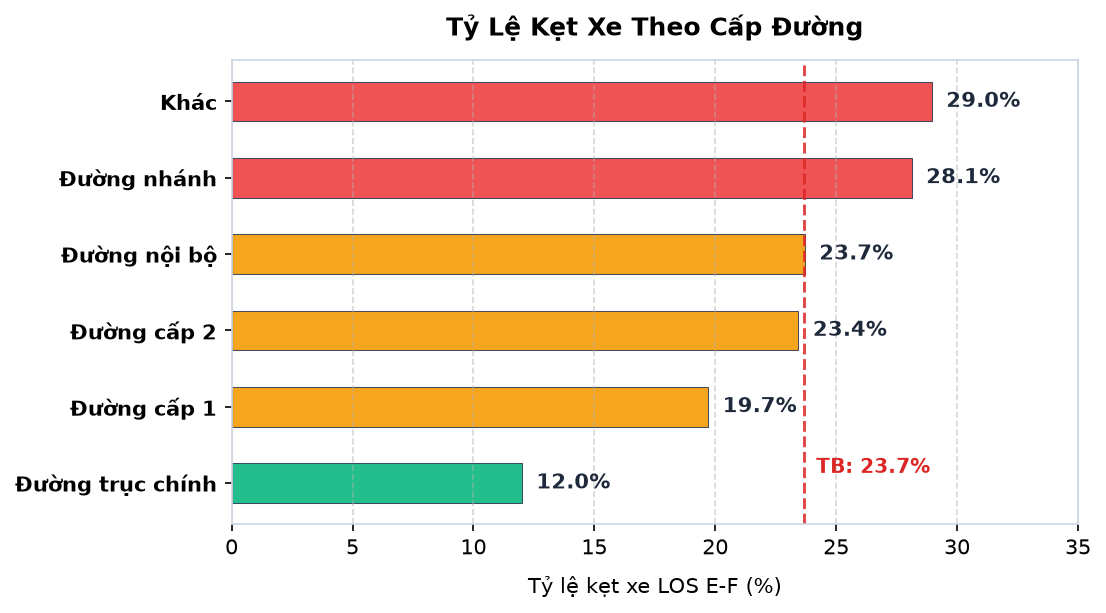

In [10]:
# Biểu đồ 2: Tỷ lệ kẹt xe (LOS E-F) theo phân cấp đường
fig, ax = plt.subplots(figsize=(7.5, 4.2))

road_names = {
    "trunk": "Đường trục chính",
    "primary": "Đường cấp 1",
    "secondary": "Đường cấp 2",
    "tertiary": "Đường nhánh",
    "unclassified": "Đường nội bộ",
    "other": "Khác",
}

stats = train_df.groupby("street_type_clean").agg(
    severe_pct=("LOS", lambda x: x.isin(["E", "F"]).mean() * 100),
).sort_values(by="severe_pct", ascending=True)

stats["label"] = stats.index.map(road_names)
city_avg = train_df["LOS"].isin(["E", "F"]).mean() * 100

bar_colors = ["#ef4444" if v >= 25 else ("#f59e0b" if v >= 15 else "#10b981") for v in stats["severe_pct"]]

y_pos = np.arange(len(stats))
bars = ax.barh(
    y_pos,
    stats["severe_pct"],
    color=bar_colors,
    height=0.52,
    edgecolor="#334155",
    linewidth=0.5,
    alpha=0.92,
)

# Đường trung bình đô thị
ax.axvline(city_avg, color="#dc2626", linestyle="--", linewidth=1.4, alpha=0.85)
ax.text(
    city_avg + 0.5,
    0.2,
    f"TB: {city_avg:.1f}%",
    color="#dc2626",
    fontweight="bold",
    fontsize=9.5,
    va="center",
)

ax.set_yticks(y_pos)
ax.set_yticklabels(stats["label"], fontweight="bold", fontsize=10)
ax.set_xlabel("Tỷ lệ kẹt xe LOS E-F (%)", fontsize=10, labelpad=8)
ax.set_xlim(0, 35)
ax.set_title("Tỷ Lệ Kẹt Xe Theo Cấp Đường", fontsize=12, fontweight="bold", pad=12)
ax.grid(axis="x", linestyle="--", alpha=0.5)

for bar, pct in zip(bars, stats["severe_pct"]):
    ax.text(
        bar.get_width() + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="#1e293b",
    )

plt.tight_layout()
plt.show()


### 4.1. Phân Tích Chuyên Sâu Biến Mục Tiêu: Mức Độ Phục Vụ Giao Thông (LOS)

Theo định nghĩa kỹ thuật giao thông (HCM - Highway Capacity Manual):
* **Cấp độ A (Free Flow):** Phương tiện di chuyển tự do với vận tốc thiết kế, lưu lượng thấp.
* **Cấp độ B - C (Stable Flow):** Dòng phương tiện ổn định, tốc độ bị ảnh hưởng nhẹ bởi mật độ xe.
* **Cấp độ D (Approaching Capacity):** Dòng xe chạm ngưỡng công suất thiết kế, bắt đầu xuất hiện xung đột giao thông.
* **Cấp độ E - F (Severe Congestion & Gridlock):** Tắc nghẽn nghiêm trọng, phương tiện phải dừng đỗ liên tục (stop-and-go).

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


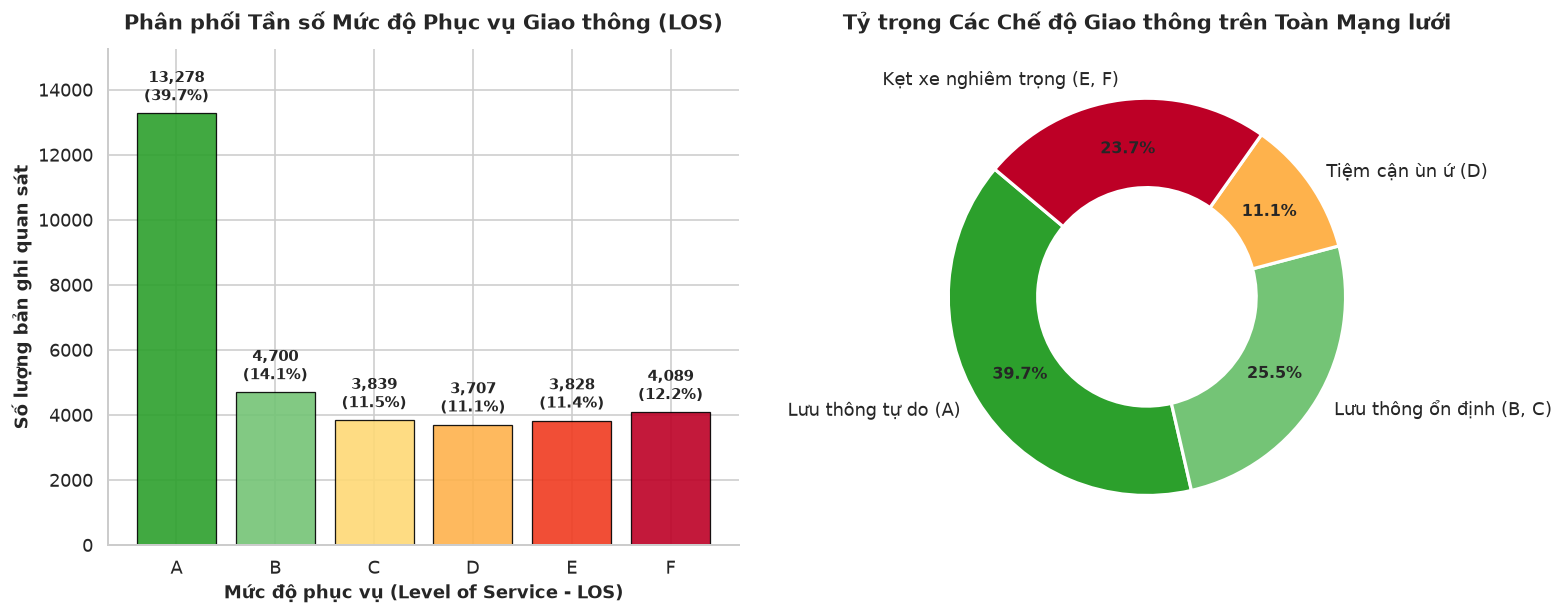

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Biểu đồ cột phân phối số lượng từng mức LOS
los_counts = train_df["LOS"].value_counts()[LOS_ORDER]
los_pcts = (los_counts / len(train_df)) * 100

bars = axes[0].bar(
    LOS_ORDER,
    los_counts.values,
    color=[LOS_COLORS[c] for c in LOS_ORDER],
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
)
axes[0].set_title("Phân phối Tần số Mức độ Phục vụ Giao thông (LOS)", pad=12)
axes[0].set_xlabel("Mức độ phục vụ (Level of Service - LOS)")
axes[0].set_ylabel("Số lượng bản ghi quan sát")
axes[0].set_ylim(0, max(los_counts.values) * 1.15)

# Thêm nhãn số lượng và phần trăm trên mỗi cột
for bar, count, pct in zip(bars, los_counts.values, los_pcts.values):
    axes[0].annotate(
        f"{count:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=9.5,
    )

# Biểu đồ tròn gom nhóm chế độ vận hành giao thông
grouped_los = pd.Series({
    "Lưu thông tự do (A)": train_df["LOS"].isin(["A"]).sum(),
    "Lưu thông ổn định (B, C)": train_df["LOS"].isin(["B", "C"]).sum(),
    "Tiệm cận ùn ứ (D)": train_df["LOS"].isin(["D"]).sum(),
    "Kẹt xe nghiêm trọng (E, F)": train_df["LOS"].isin(["E", "F"]).sum(),
})

group_colors = ["#2ca02c", "#74c476", "#feb24c", "#bd0026"]
wedges, texts, autotexts = axes[1].pie(
    grouped_los.values,
    labels=grouped_los.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=group_colors,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2),
    pctdistance=0.75,
)
for at in autotexts:
    at.set_fontweight("bold")
    at.set_fontsize(10)
axes[1].set_title("Tỷ trọng Các Chế độ Giao thông trên Toàn Mạng lưới", pad=12)

plt.tight_layout()
plt.show()

### 4.2. Phân Tích Động Học Thời Gian & Giờ Cao Điểm (Temporal Dynamics)

Khảo sát sự biến thiên của tình trạng giao thông theo chu kỳ 24 giờ và các ngày trong tuần:
1. **Diễn biến tỷ lệ từng mức LOS theo 24 giờ:** Xác định chính xác hai đỉnh ùn tắc (morning rush và evening rush).
2. **Chỉ số Ùn tắc Trung bình (Average LOS Score):** Đo lường mức độ căng thẳng giao thông theo từng nửa giờ.
3. **Heatmap Khung giờ × Thứ trong tuần:** So sánh mức độ ùn tắc giữa ngày đi làm (Thứ 2 – Thứ 6) và ngày nghỉ (Thứ 7 – Chủ Nhật).

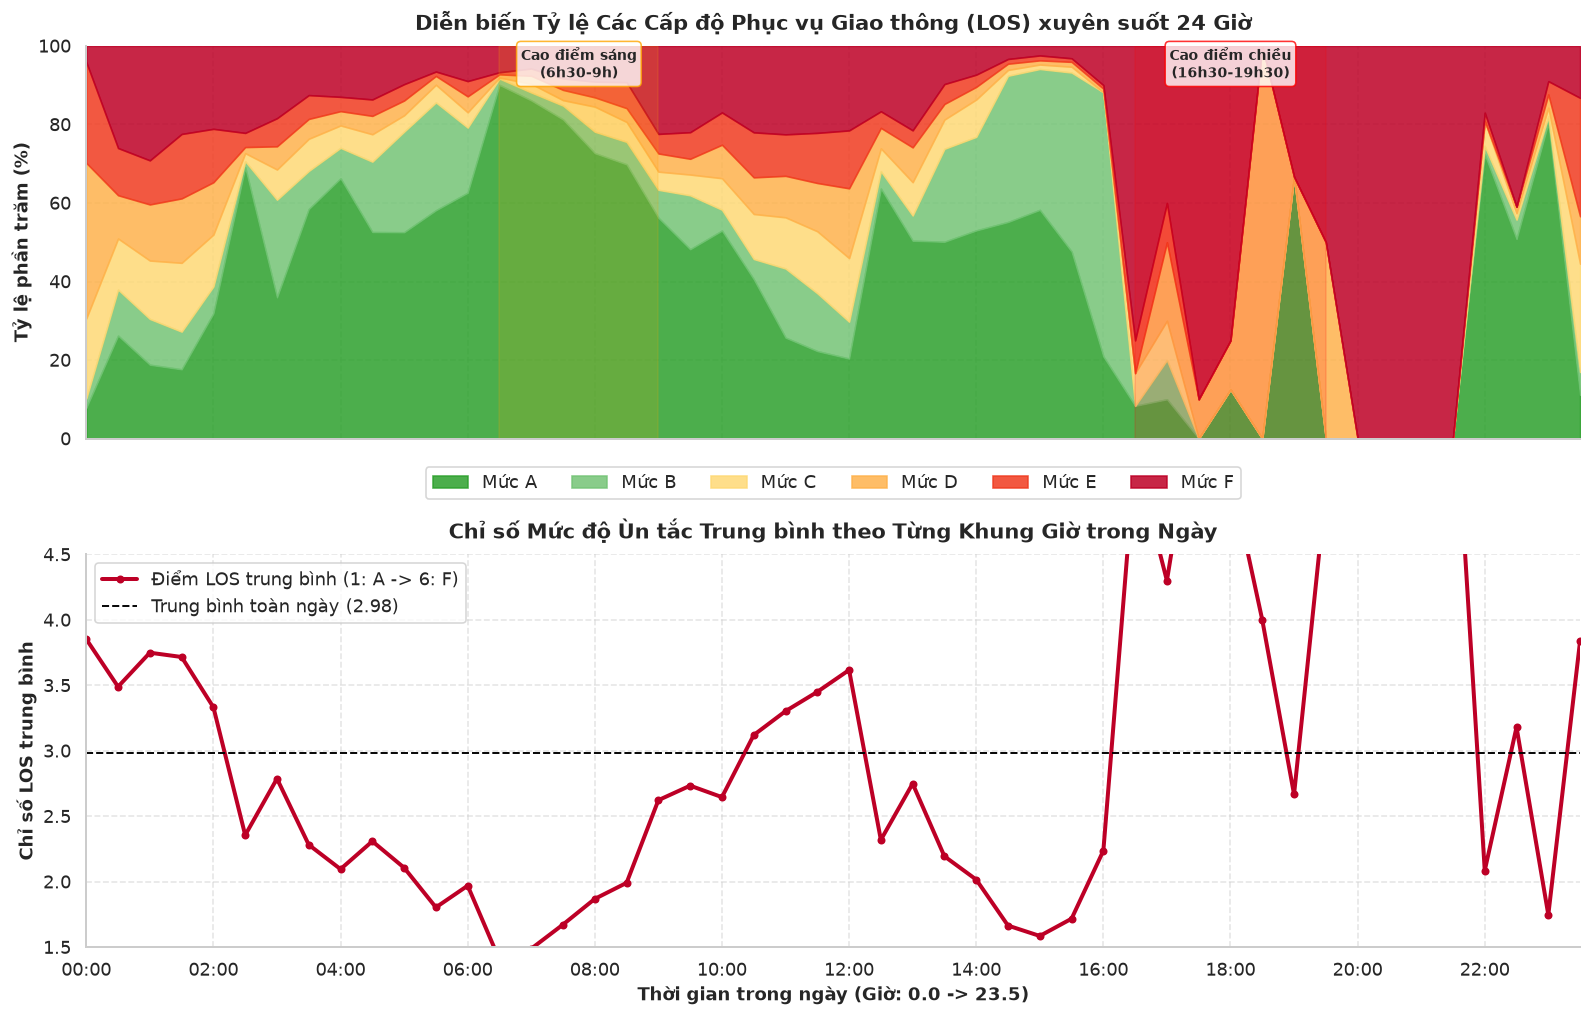

In [6]:
# 1. Tính toán tỷ lệ phần trăm từng mức LOS theo khung giờ
hourly_los = train_df.groupby(["hour_float", "LOS"]).size().unstack(fill_value=0)
hourly_los_pct = hourly_los.div(hourly_los.sum(axis=1), axis=0) * 100

# 2. Tính chỉ số ùn tắc trung bình
hourly_score = train_df.groupby("hour_float")["LOS_score"].mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Subplot 1: Stacked Area Chart tỷ lệ phần trăm các mức LOS
hours = hourly_los_pct.index
cumulative_y = np.zeros(len(hours))
for los in LOS_ORDER:
    values = hourly_los_pct[los].values
    ax1.fill_between(
        hours,
        cumulative_y,
        cumulative_y + values,
        label=f"Mức {los}",
        color=LOS_COLORS[los],
        alpha=0.85,
    )
    cumulative_y += values

ax1.set_ylabel("Tỷ lệ phần trăm (%)")
ax1.set_title("Diễn biến Tỷ lệ Các Cấp độ Phục vụ Giao thông (LOS) xuyên suốt 24 Giờ", pad=10)
ax1.set_ylim(0, 100)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=6, frameon=True)
ax1.grid(True, linestyle="--", alpha=0.5)

# Đánh dấu vùng giờ cao điểm
ax1.axvspan(6.5, 9.0, color="orange", alpha=0.15, label="Cao điểm sáng")
ax1.axvspan(16.5, 19.5, color="red", alpha=0.15, label="Cao điểm chiều")
ax1.text(7.75, 92, "Cao điểm sáng\n(6h30-9h)", ha="center", fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="orange", alpha=0.8))
ax1.text(18.0, 92, "Cao điểm chiều\n(16h30-19h30)", ha="center", fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="red", alpha=0.8))

# Subplot 2: Chỉ số ùn tắc trung bình
ax2.plot(hourly_score.index, hourly_score.values, color="#bd0026", linewidth=2.5, marker="o", markersize=4, label="Điểm LOS trung bình (1: A -> 6: F)")
ax2.axhline(hourly_score.mean(), color="black", linestyle="--", linewidth=1.2, label=f"Trung bình toàn ngày ({hourly_score.mean():.2f})")
ax2.set_xlabel("Thời gian trong ngày (Giờ: 0.0 -> 23.5)")
ax2.set_ylabel("Chỉ số LOS trung bình")
ax2.set_title("Chỉ số Mức độ Ùn tắc Trung bình theo Từng Khung Giờ trong Ngày", pad=10)
ax2.set_xticks(range(0, 25, 2))
ax2.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 2)])
ax2.set_xlim(0, 23.5)
ax2.set_ylim(1.5, 4.5)
ax2.legend(loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

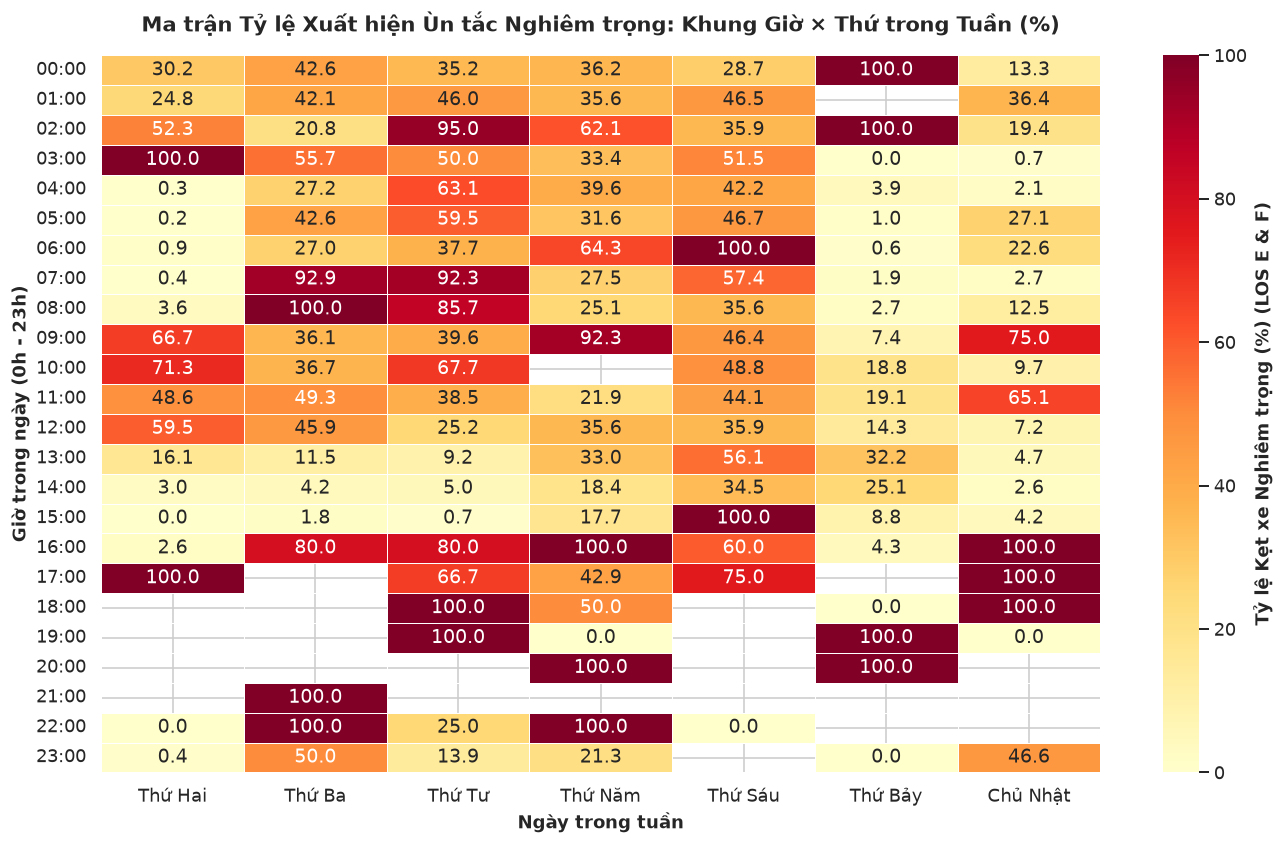

In [7]:
# Tạo ma trận Tỷ lệ Kẹt xe Nghiêm trọng (LOS E & F) theo Giờ x Thứ trong tuần
heatmap_data = train_df.pivot_table(
    index="hour_int",
    columns="weekday_vn",
    values="is_severe_congestion",
    aggfunc="mean",
)[WEEKDAY_VN] * 100

plt.figure(figsize=(12, 7.5))
ax = sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    cbar_kws={"label": "Tỷ lệ Kẹt xe Nghiêm trọng (%) (LOS E & F)"},
    linewidths=0.5,
    linecolor="white",
)
plt.title("Ma trận Tỷ lệ Xuất hiện Ùn tắc Nghiêm trọng: Khung Giờ × Thứ trong Tuần (%)", pad=15)
plt.xlabel("Ngày trong tuần")
plt.ylabel("Giờ trong ngày (0h - 23h)")
plt.yticks(ticks=np.arange(0.5, 24.5, 1), labels=[f"{h:02d}:00" for h in range(24)], rotation=0)
plt.tight_layout()
plt.show()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


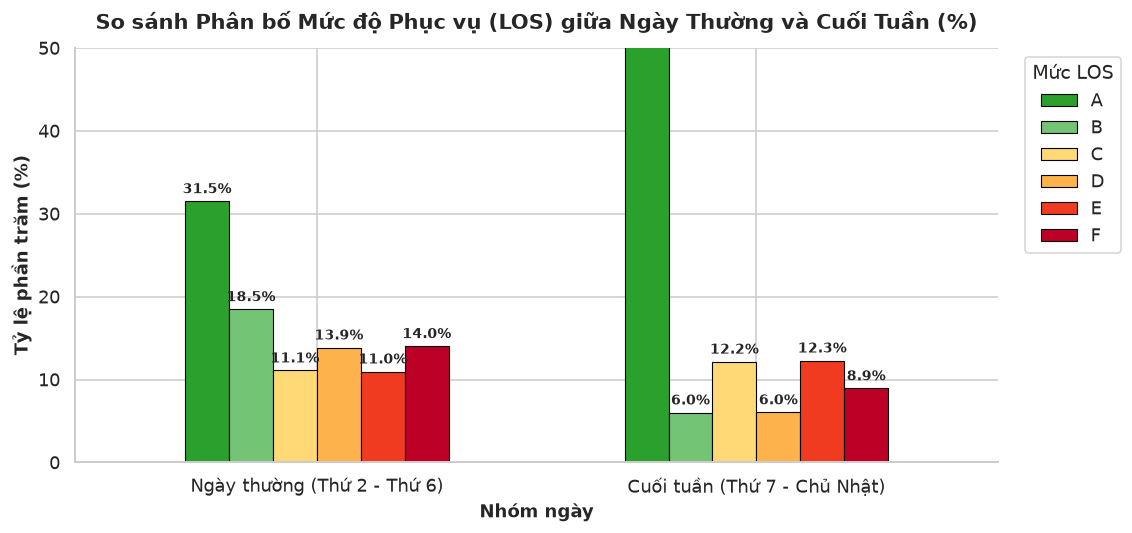

In [8]:
# So sánh phân bố LOS giữa Ngày thường (Thứ 2 - 6) và Cuối tuần (Thứ 7 - CN)
day_type_df = train_df.groupby(["is_weekend", "LOS"]).size().unstack(fill_value=0)
day_type_pct = day_type_df.div(day_type_df.sum(axis=1), axis=0) * 100
day_type_pct.index = ["Ngày thường (Thứ 2 - Thứ 6)", "Cuối tuần (Thứ 7 - Chủ Nhật)"]

fig, ax = plt.subplots(figsize=(10, 4.8))
day_type_pct.plot(
    kind="bar",
    color=[LOS_COLORS[c] for c in LOS_ORDER],
    edgecolor="black",
    linewidth=0.7,
    ax=ax,
    rot=0,
    width=0.6,
)
ax.set_title("So sánh Phân bố Mức độ Phục vụ (LOS) giữa Ngày Thường và Cuối Tuần (%)", pad=12)
ax.set_ylabel("Tỷ lệ phần trăm (%)")
ax.set_xlabel("Nhóm ngày")
ax.legend(title="Mức LOS", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_ylim(0, 50)

# Thêm nhãn giá trị
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8.5, fontweight="semibold")

plt.tight_layout()
plt.show()

### 4.3. Cấu Trúc Mạng Lưới Đường Bộ & Tác Động Đến Ùn Tắc (Road Network Hierarchy)

Khảo sát mối liên hệ giữa các đặc tính hình học và phân loại đường với mức độ kẹt xe:
1. **Phân phối chiều dài đoạn đường (`length`):** Phân đoạn đường trong đô thị thường có chiều dài bao nhiêu mét?
2. **Tỷ trọng ùn tắc theo loại đường (`street_type`):** Đường trục (`trunk`), đường cấp 1 (`primary`), hay đường nhánh (`tertiary`) chịu tải tắc nghẽn lớn nhất?
3. **Top 15 Tuyến đường có số lượt ùn tắc nghiêm trọng cao nhất TP.HCM.**

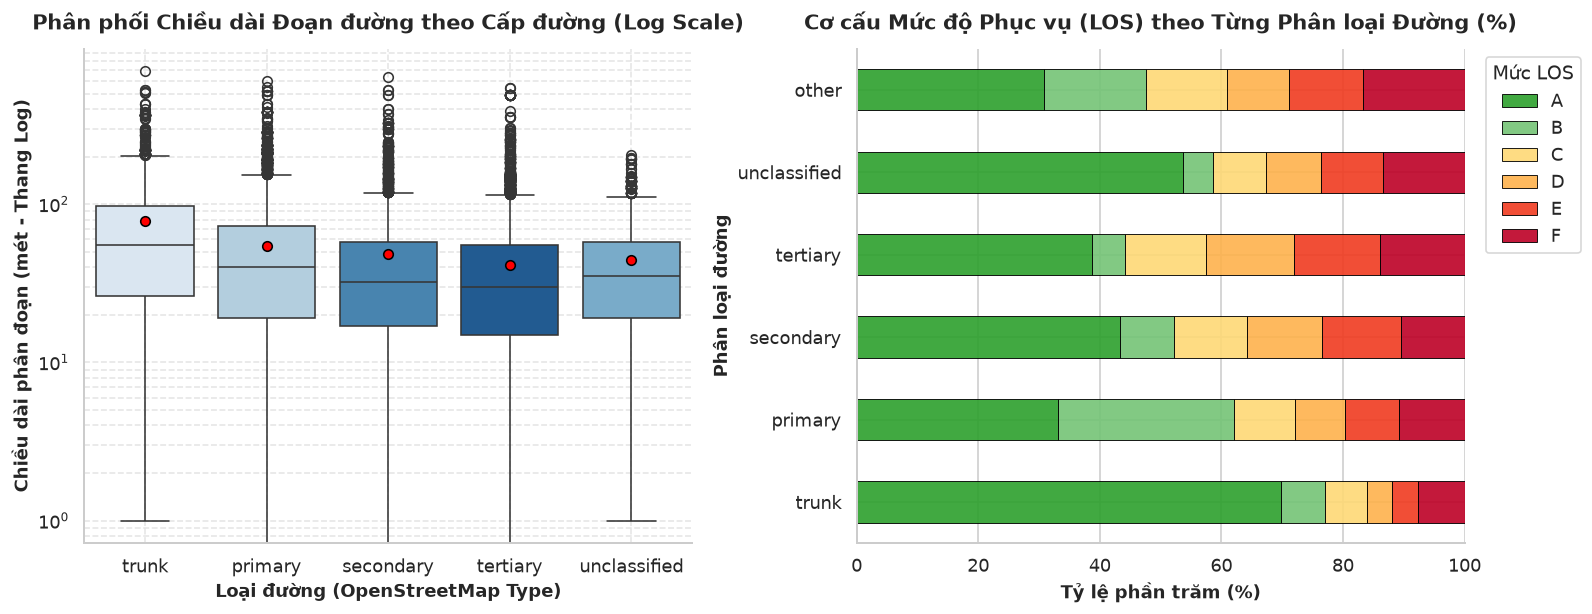

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Phân phối chiều dài đoạn đường theo phân loại đường chính (log scale)
main_roads = ["trunk", "primary", "secondary", "tertiary", "unclassified"]
df_main_roads = train_df[train_df["street_type_clean"].isin(main_roads)]

sns.boxplot(
    data=df_main_roads,
    x="street_type_clean",
    y="length",
    hue="street_type_clean",
    order=main_roads,
    palette="Blues_r",
    ax=ax1,
    legend=False,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 6},
)
ax1.set_yscale("log")
ax1.set_title("Phân phối Chiều dài Đoạn đường theo Cấp đường (Log Scale)", pad=12)
ax1.set_xlabel("Loại đường (OpenStreetMap Type)")
ax1.set_ylabel("Chiều dài phân đoạn (mét - Thang Log)")
ax1.grid(True, which="both", linestyle="--", alpha=0.5)

# 2. Tỷ lệ phần trăm các mức LOS theo phân loại đường
type_los_pct = (
    train_df.groupby("street_type_clean")["LOS"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)[LOS_ORDER]
    .loc[main_roads + ["other"]] * 100
)

type_los_pct.plot(
    kind="barh",
    stacked=True,
    color=[LOS_COLORS[c] for c in LOS_ORDER],
    edgecolor="black",
    linewidth=0.6,
    ax=ax2,
    alpha=0.9,
)
ax2.set_title("Cơ cấu Mức độ Phục vụ (LOS) theo Từng Phân loại Đường (%)", pad=12)
ax2.set_xlabel("Tỷ lệ phần trăm (%)")
ax2.set_ylabel("Phân loại đường")
ax2.set_xlim(0, 100)
ax2.legend(title="Mức LOS", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

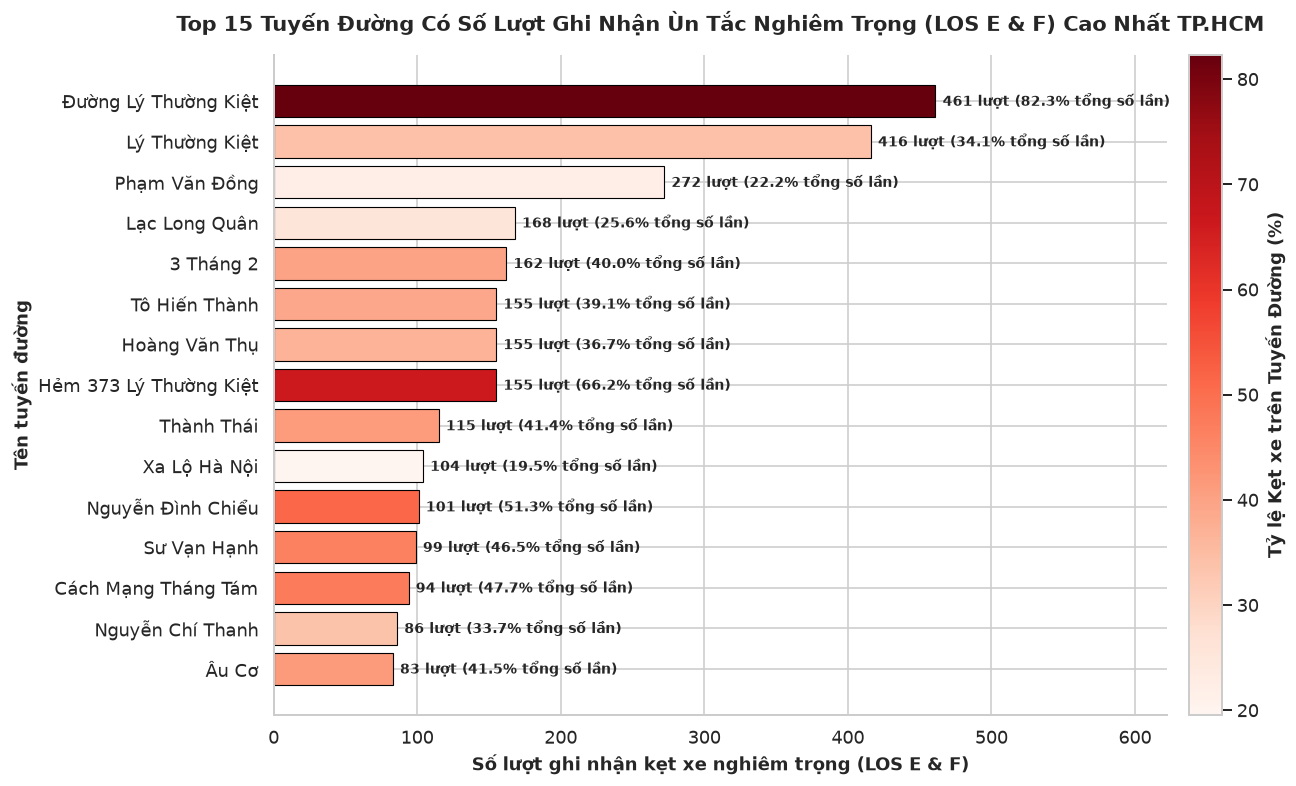

In [10]:
# Thống kê Top 15 tuyến đường có số lượt ghi nhận kẹt xe nghiêm trọng (LOS E & F) nhiều nhất
street_congestion = (
    train_df.groupby("street_name")
    .agg(
        tong_quan_sat=("is_severe_congestion", "count"),
        so_luot_ket=("is_severe_congestion", "sum"),
        ty_le_ket=("is_severe_congestion", "mean"),
    )
    .query("tong_quan_sat >= 100")  # Lọc các tuyến có tối thiểu 100 lượt quan sát
    .sort_values(by="so_luot_ket", ascending=True)
    .tail(15)
)

street_congestion["ty_le_ket_pct"] = street_congestion["ty_le_ket"] * 100

plt.figure(figsize=(12, 7))
norm = plt.Normalize(street_congestion["ty_le_ket_pct"].min(), street_congestion["ty_le_ket_pct"].max())
cmap = plt.cm.Reds

bars = plt.barh(
    street_congestion.index,
    street_congestion["so_luot_ket"],
    color=cmap(norm(street_congestion["ty_le_ket_pct"])),
    edgecolor="black",
    linewidth=0.7,
)

plt.title("Top 15 Tuyến Đường Có Số Lượt Ghi Nhận Ùn Tắc Nghiêm Trọng (LOS E & F) Cao Nhất TP.HCM", pad=15)
plt.xlabel("Số lượt ghi nhận kẹt xe nghiêm trọng (LOS E & F)")
plt.ylabel("Tên tuyến đường")

# Thêm nhãn số lượt và tỷ lệ phần trăm
for bar, row in zip(bars, street_congestion.itertuples()):
    plt.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{row.so_luot_ket:,} lượt ({row.ty_le_ket_pct:.1f}% tổng số lần)",
        va="center",
        ha="left",
        fontweight="bold",
        fontsize=9,
    )

# Thêm colorbar hiển thị tỷ lệ kẹt
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), orientation="vertical", pad=0.02)
cbar.set_label("Tỷ lệ Kẹt xe trên Tuyến Đường (%)")

plt.xlim(0, max(street_congestion["so_luot_ket"]) * 1.35)
plt.tight_layout()
plt.show()

### 4.4. Động Học Vận Tốc Thực Tế (`segment_status.csv`)

Tệp dữ liệu `segment_status.csv` ghi nhận 90.938 mẫu vận tốc phương tiện tức thời (`velocity` tính bằng km/h) đo đạc từ các thiết bị giám sát.
Phần này phân tích:
1. Phân phối vận tốc thực tế, các ngưỡng tứ phân vị (25%, 50%, 75%).
2. Nhận diện các giá trị vận tốc ngoại lai (outliers như vận tốc cực đoan > 100 km/h do lỗi cảm biến).
3. Diễn biến vận tốc thực tế theo từng giờ trong ngày.

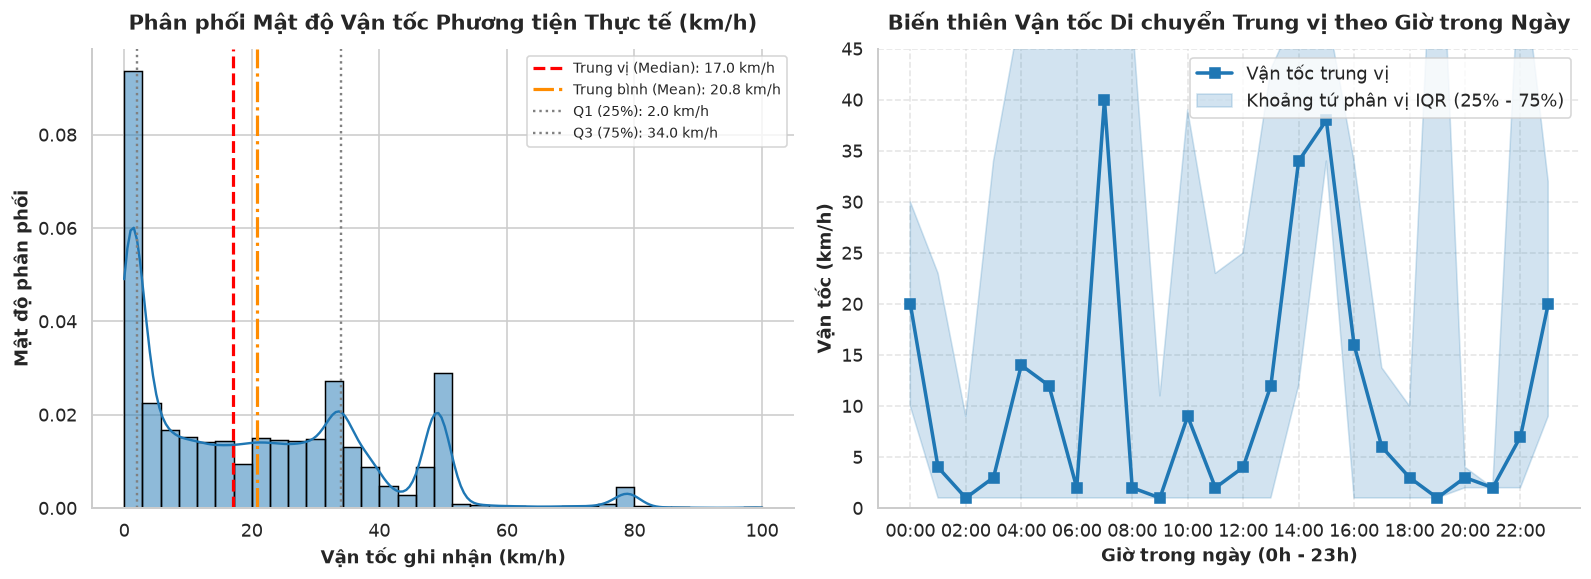

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# 1. Phân phối vận tốc thực tế (lọc bỏ các giá trị nhiễu > 120 km/h để hiển thị chi tiết vùng đô thị)
v_urban = seg_status_df["velocity"][seg_status_df["velocity"] <= 100]

sns.histplot(v_urban, bins=35, kde=True, color="#1f77b4", edgecolor="black", ax=ax1, stat="density")
median_v = seg_status_df["velocity"].median()
mean_v = seg_status_df["velocity"].mean()
q25_v = seg_status_df["velocity"].quantile(0.25)
q75_v = seg_status_df["velocity"].quantile(0.75)

ax1.axvline(median_v, color="red", linestyle="--", linewidth=2, label=f"Trung vị (Median): {median_v:.1f} km/h")
ax1.axvline(mean_v, color="darkorange", linestyle="-.", linewidth=2, label=f"Trung bình (Mean): {mean_v:.1f} km/h")
ax1.axvline(q25_v, color="gray", linestyle=":", linewidth=1.5, label=f"Q1 (25%): {q25_v:.1f} km/h")
ax1.axvline(q75_v, color="gray", linestyle=":", linewidth=1.5, label=f"Q3 (75%): {q75_v:.1f} km/h")

ax1.set_title("Phân phối Mật độ Vận tốc Phương tiện Thực tế (km/h)", pad=12)
ax1.set_xlabel("Vận tốc ghi nhận (km/h)")
ax1.set_ylabel("Mật độ phân phối")
ax1.legend(loc="upper right", fontsize=9)

# 2. Vận tốc trung vị và khoảng tứ phân vị theo từng giờ trong ngày
hourly_v = seg_status_df.groupby("hour")["velocity"].agg(
    median="median",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
)

hours_range = hourly_v.index
ax2.plot(hours_range, hourly_v["median"], color="#1f77b4", marker="s", linewidth=2.2, label="Vận tốc trung vị")
ax2.fill_between(hours_range, hourly_v["q25"], hourly_v["q75"], color="#1f77b4", alpha=0.2, label="Khoảng tứ phân vị IQR (25% - 75%)")
ax2.set_title("Biến thiên Vận tốc Di chuyển Trung vị theo Giờ trong Ngày", pad=12)
ax2.set_xlabel("Giờ trong ngày (0h - 23h)")
ax2.set_ylabel("Vận tốc (km/h)")
ax2.set_xticks(range(0, 24, 2))
ax2.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
ax2.set_ylim(0, 45)
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 4.5. Khảo Sát Không Gian Địa Lý Mạng Lưới Giao Thông TP.HCM (Geospatial Analysis)

Tọa độ địa lý từ `long_snode`, `lat_snode`, `long_enode`, `lat_enode` cho phép tái dựng mạng lưới đồ thị giao thông thực tế:
1. **Bản đồ khung mạng lưới đường bộ:** Phân bố hình học các phân đoạn đường theo cấp loại đường tại TP.HCM.
2. **Bản đồ điểm nóng ùn tắc không gian (Spatial Bottlenecks):** Tỷ lệ kẹt xe trung bình tại từng vị trí, làm nổi bật các khu vực trọng điểm (trục đường quanh khuôn viên Trường ĐH Bách Khoa Quận 10, trục Phạm Văn Đồng, Xa Lộ Hà Nội, Quốc Lộ 1).

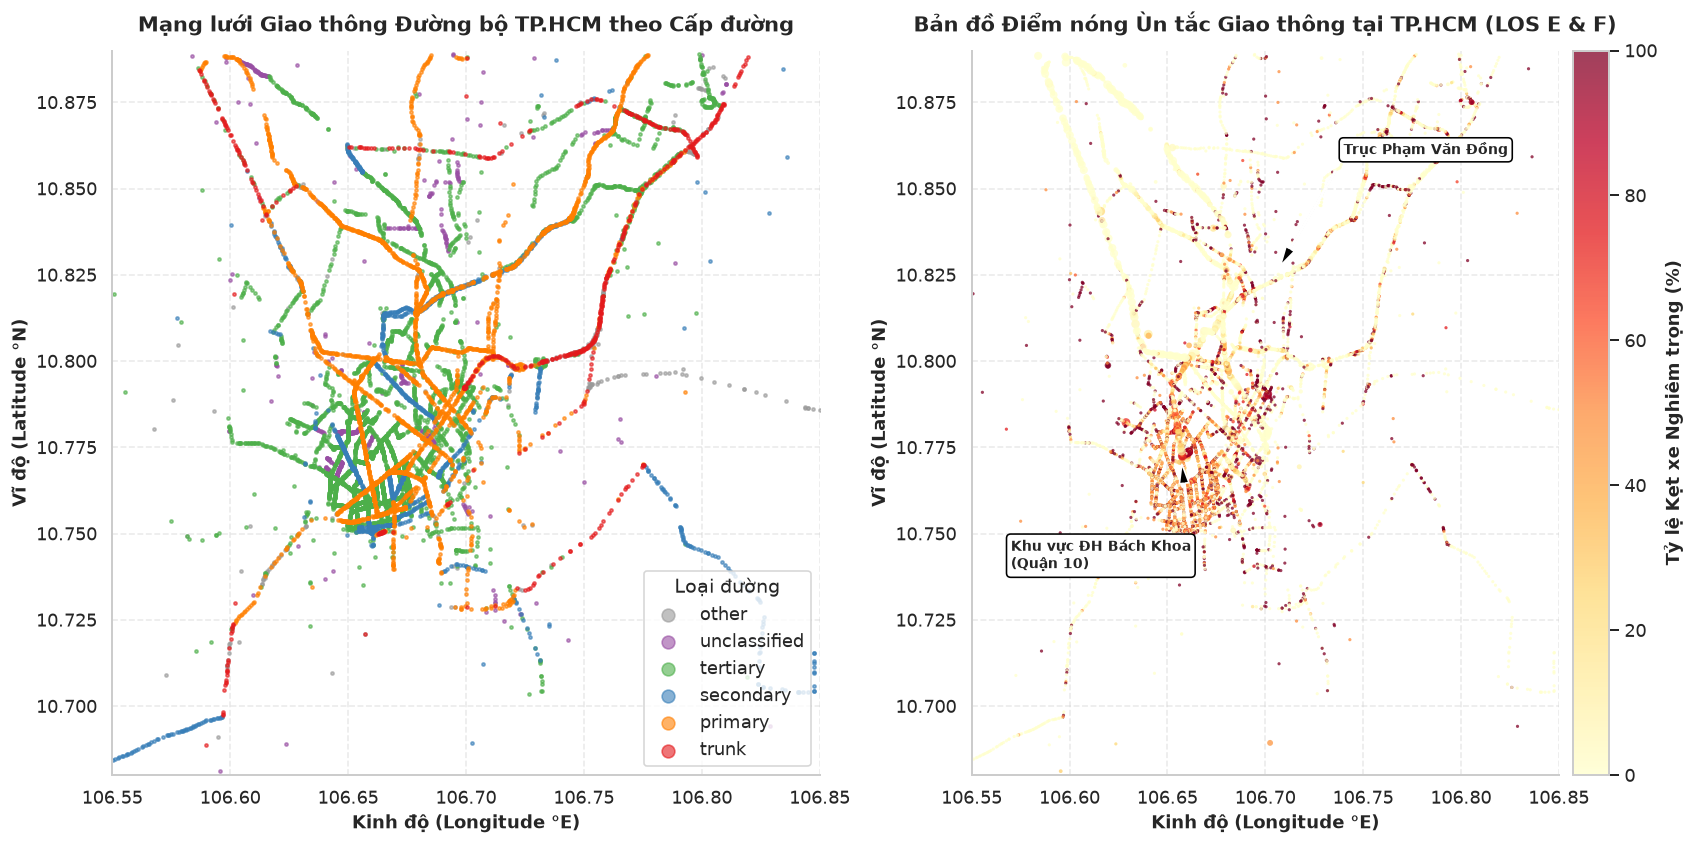

In [12]:
# Tổng hợp tọa độ trung bình và tỷ lệ kẹt xe của từng phân đoạn đường
segment_geo = train_df.groupby("segment_id").agg(
    long=("long_snode", "first"),
    lat=("lat_snode", "first"),
    street_type=("street_type_clean", "first"),
    street_name=("street_name", "first"),
    length=("length", "first"),
    total_records=("is_severe_congestion", "count"),
    congestion_rate=("is_severe_congestion", "mean"),
    avg_los_score=("LOS_score", "mean"),
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.5))

# 1. Bản đồ mạng lưới đường bộ theo loại đường
road_type_colors = {
    "trunk": "#e41a1c",        # Đỏ - Trục chính
    "primary": "#ff7f00",      # Cam - Cấp 1
    "secondary": "#377eb8",    # Xanh dương - Cấp 2
    "tertiary": "#4daf4a",     # Xanh lá - Cấp 3
    "unclassified": "#984ea3", # Tím
    "other": "#999999",        # Xám
}

for r_type in ["other", "unclassified", "tertiary", "secondary", "primary", "trunk"]:
    sub = segment_geo[segment_geo["street_type"] == r_type]
    ax1.scatter(
        sub["long"],
        sub["lat"],
        s=4,
        alpha=0.6,
        color=road_type_colors.get(r_type, "#999999"),
        label=r_type,
    )

ax1.set_title("Mạng lưới Giao thông Đường bộ TP.HCM theo Cấp đường", pad=12)
ax1.set_xlabel("Kinh độ (Longitude °E)")
ax1.set_ylabel("Vĩ độ (Latitude °N)")
ax1.set_xlim(106.55, 106.85)
ax1.set_ylim(10.68, 10.89)
ax1.legend(title="Loại đường", markerscale=4, loc="lower right")
ax1.grid(True, linestyle="--", alpha=0.4)

# 2. Bản đồ Điểm nóng Ùn tắc (Spatial Congestion Hotspots)
sc = ax2.scatter(
    segment_geo["long"],
    segment_geo["lat"],
    c=segment_geo["congestion_rate"] * 100,
    cmap="YlOrRd",
    s=np.clip(segment_geo["total_records"] * 0.8, 4, 30),
    alpha=0.75,
    edgecolors="none",
)
cbar = plt.colorbar(sc, ax=ax2, pad=0.02)
cbar.set_label("Tỷ lệ Kẹt xe Nghiêm trọng (%)")

# Chú thích các khu vực nút thắt trọng điểm
ax2.annotate("Khu vực ĐH Bách Khoa\n(Quận 10)", xy=(106.657, 10.772), xytext=(106.57, 10.74),
             arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6),
             fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

ax2.annotate("Trục Phạm Văn Đồng", xy=(106.705, 10.825), xytext=(106.74, 10.86),
             arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6),
             fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

ax2.set_title("Bản đồ Điểm nóng Ùn tắc Giao thông tại TP.HCM (LOS E & F)", pad=12)
ax2.set_xlabel("Kinh độ (Longitude °E)")
ax2.set_ylabel("Vĩ độ (Latitude °N)")
ax2.set_xlim(106.55, 106.85)
ax2.set_ylim(10.68, 10.89)
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

*Hình ảnh minh họa: Toàn cảnh cấu trúc mạng lưới phân cấp đường bộ và phân bố không gian giao thông TP.HCM.*


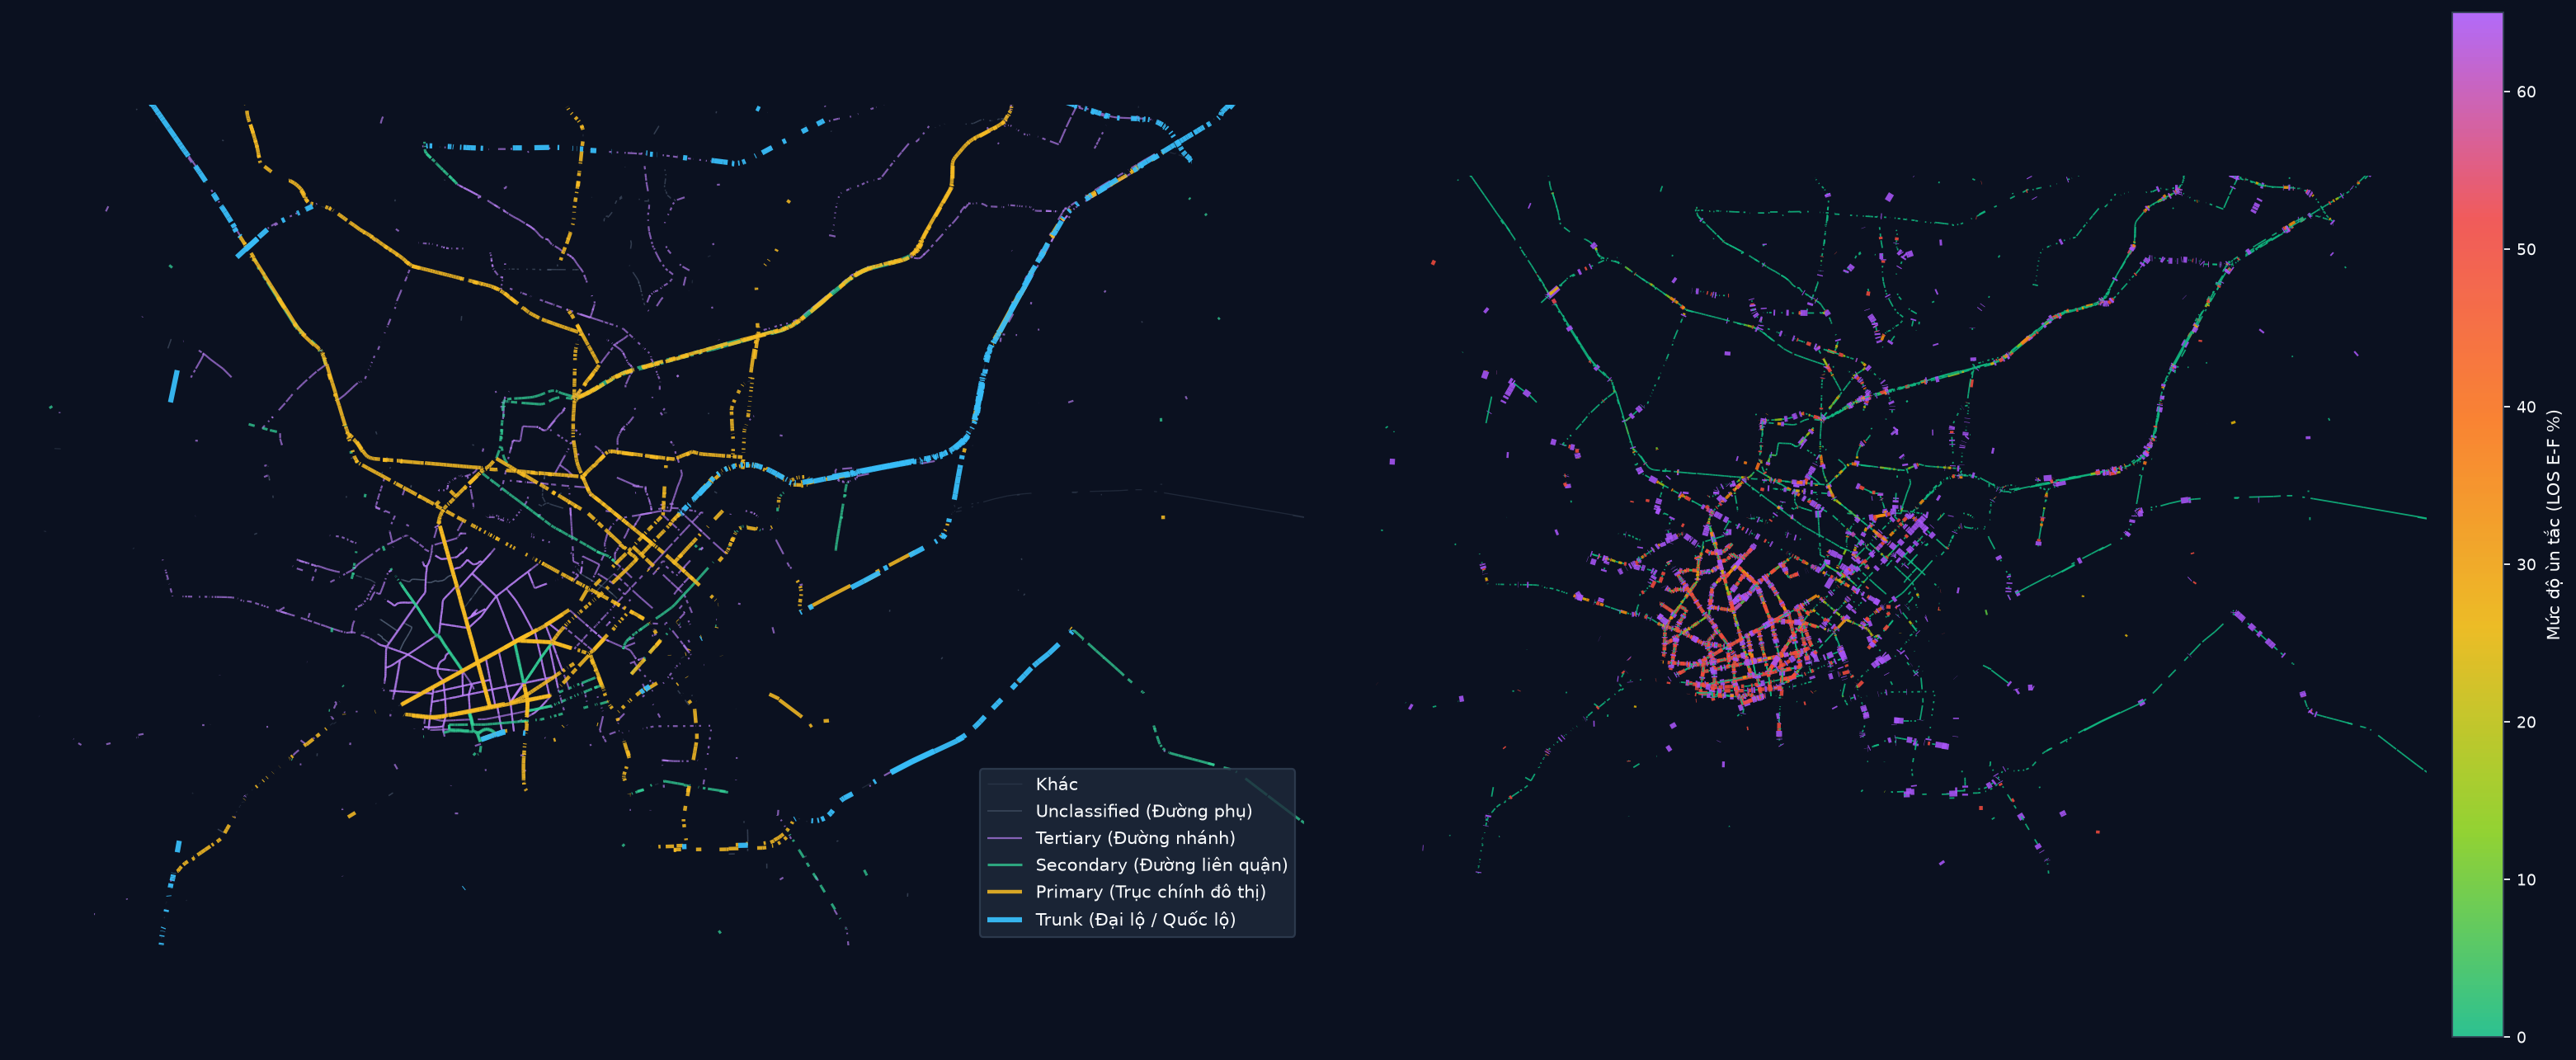

In [13]:
# ==============================================================================
# HÌNH MINH HỌA: TOÀN CẢNH MẠNG LƯỚI ĐƯỜNG BỘ & KHÔNG GIAN GIAO THÔNG TP.HCM
# ==============================================================================

from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap

# 1. Trích xuất và tổng hợp dữ liệu tọa độ không gian cho từng phân đoạn đường
seg_geo_summary = train_df.groupby("segment_id").agg(
    s_long=("long_snode", "first"),
    s_lat=("lat_snode", "first"),
    e_long=("long_enode", "first"),
    e_lat=("lat_enode", "first"),
    street_type=("street_type_clean", "first"),
    street_name=("street_name", "first"),
    congestion_rate=("is_severe_congestion", "mean"),
    total_records=("is_severe_congestion", "count"),
    length=("length", "first"),
).reset_index()

# Lọc tọa độ thuộc phạm vi đô thị trọng điểm TP.HCM
geo_mask = (
    seg_geo_summary["s_long"].between(106.55, 106.85)
    & seg_geo_summary["e_long"].between(106.55, 106.85)
    & seg_geo_summary["s_lat"].between(10.68, 10.89)
    & seg_geo_summary["e_lat"].between(10.68, 10.89)
)
seg_geo_filtered = seg_geo_summary[geo_mask]

# Danh sách vector các phân đoạn đường [(x_start, y_start), (x_end, y_end)]
vector_lines = [
    [(row.s_long, row.s_lat), (row.e_long, row.e_lat)]
    for row in seg_geo_filtered.itertuples()
]

# Tỷ lệ co giãn chuẩn Mercator tại vĩ độ TP.HCM (~10.78°N)
mercator_aspect = 1.0 / np.cos(np.radians(10.78))

# Khung hình toàn cảnh ngang (Landscape Panorama 21:9) - Tinh giản chỉ để hình minh họa
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 9), facecolor="#0b1120")

# --- HÌNH MINH HỌA 1: Khung Mạng Lưới Phân Cấp Đường Bộ ---
ax1.set_facecolor("#0b1120")
road_hierarchy_styles = {
    "trunk": {"color": "#38bdf8", "lw": 2.8, "alpha": 0.95, "label": "Trunk (Đại lộ / Quốc lộ)"},
    "primary": {"color": "#fbbf24", "lw": 2.0, "alpha": 0.85, "label": "Primary (Trục chính đô thị)"},
    "secondary": {"color": "#34d399", "lw": 1.4, "alpha": 0.75, "label": "Secondary (Đường liên quận)"},
    "tertiary": {"color": "#c084fc", "lw": 1.0, "alpha": 0.65, "label": "Tertiary (Đường nhánh)"},
    "unclassified": {"color": "#64748b", "lw": 0.7, "alpha": 0.45, "label": "Unclassified (Đường phụ)"},
    "other": {"color": "#475569", "lw": 0.6, "alpha": 0.35, "label": "Khác"},
}

for r_type in ["other", "unclassified", "tertiary", "secondary", "primary", "trunk"]:
    sub = seg_geo_filtered[seg_geo_filtered["street_type"] == r_type]
    sub_lines = [[(r.s_long, r.s_lat), (r.e_long, r.e_lat)] for r in sub.itertuples()]
    st = road_hierarchy_styles[r_type]
    lc = LineCollection(sub_lines, colors=st["color"], linewidths=st["lw"], alpha=st["alpha"], label=st["label"])
    ax1.add_collection(lc)

ax1.set_xlim(106.57, 106.82)
ax1.set_ylim(10.71, 10.87)
ax1.set_aspect(mercator_aspect)
ax1.axis("off")

leg = ax1.legend(loc="lower right", facecolor="#1e293b", edgecolor="#334155", fontsize=9.5)
for text in leg.get_texts():
    text.set_color("#f8fafc")

# --- HÌNH MINH HỌA 2: Phân Bố Cường Độ Không Gian Giao Thông ---
ax2.set_facecolor("#0b1120")
heat_colors = ["#10b981", "#84cc16", "#eab308", "#f97316", "#ef4444", "#a855f7"]
traffic_cmap = LinearSegmentedColormap.from_list("traffic_heat", heat_colors, N=256)

congestion_percentages = seg_geo_filtered["congestion_rate"].values * 100
dynamic_lws = 0.8 + (congestion_percentages / 100.0) * 2.4

lc_heat = LineCollection(vector_lines, cmap=traffic_cmap, norm=plt.Normalize(0, 65), linewidths=dynamic_lws, alpha=0.88)
lc_heat.set_array(congestion_percentages)
ax2.add_collection(lc_heat)

ax2.set_xlim(106.57, 106.82)
ax2.set_ylim(10.71, 10.87)
ax2.set_aspect(mercator_aspect)
ax2.axis("off")

cbar = plt.colorbar(lc_heat, ax=ax2, pad=0.02, shrink=0.88)
cbar.set_label("Mức độ ùn tắc (LOS E-F %)", color="#f8fafc", fontsize=9.5)
cbar.ax.tick_params(colors="#f8fafc", labelsize=8.5)
cbar.outline.set_edgecolor("#334155")

plt.subplots_adjust(left=0.01, right=0.96, top=0.99, bottom=0.01, wspace=0.04)
plt.show()


### 4.6. Ma Trận Tương Quan Tuyến Tính & Phi Tuyến (Correlation Analysis)

Tính toán ma trận tương quan giữa các đặc trưng số học:
* `hour_float`: Khung giờ trong ngày (tính liên tục).
* `weekday`: Thứ trong tuần (0: Thứ 2 đến 6: Chủ Nhật).
* `is_weekend`: Cờ ngày cuối tuần (0: ngày thường, 1: cuối tuần).
* `length`: Chiều dài phân đoạn đường (mét).
* `street_level`: Cấp bậc phân loại tuyến đường (1 đến 4).
* `LOS_score`: Mức độ phục vụ số hóa (1: A đến 6: F).
* `is_severe_congestion`: Cờ kẹt xe nghiêm trọng (0 hoặc 1).

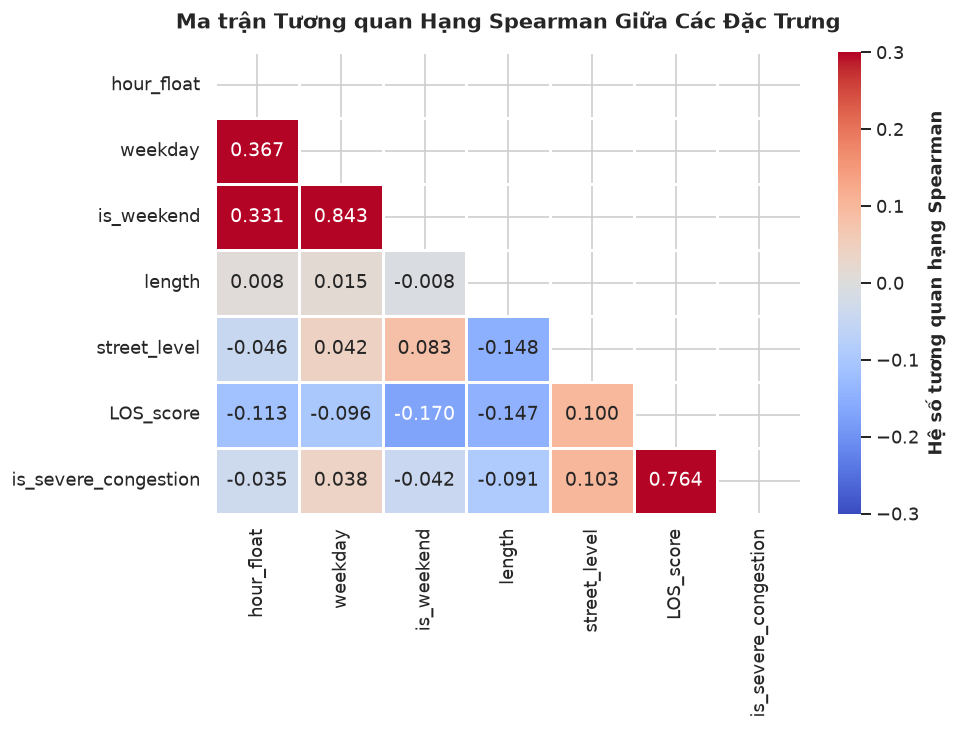

In [13]:
corr_features = [
    "hour_float",
    "weekday",
    "is_weekend",
    "length",
    "street_level",
    "LOS_score",
    "is_severe_congestion",
]

corr_matrix = train_df[corr_features].corr(method="spearman")

plt.figure(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-0.3,
    vmax=0.3,
    center=0,
    linewidths=0.8,
    cbar_kws={"label": "Hệ số tương quan hạng Spearman"},
)
plt.title("Ma trận Tương quan Hạng Spearman Giữa Các Đặc Trưng", pad=15)
plt.tight_layout()
plt.show()

## 5. Tổng Kết Phát Hiện Cốt Lõi & Khuyến Nghị Kỹ Thuật (Key Insights & Recommendations)

Dưới đây là bảng tổng hợp các chỉ số định lượng then chốt thu được từ quá trình phân tích khám phá dữ liệu (EDA):

In [14]:
# Tổng hợp bảng chỉ số nghiệp vụ định lượng
morning_peak = train_df[train_df["time_of_day"] == "Cao điểm sáng (6h30-9h)"]["is_severe_congestion"].mean() * 100
evening_peak = train_df[train_df["time_of_day"] == "Cao điểm chiều (16h30-19h30)"]["is_severe_congestion"].mean() * 100
night_congestion = train_df[train_df["time_of_day"] == "Đêm/Sáng sớm (0h-6h)"]["is_severe_congestion"].mean() * 100

summary_kpi = [
    {"Chỉ số Nghiệp vụ": "Tổng số bản ghi tập Train", "Giá trị": f"{len(train_df):,} dòng"},
    {"Chỉ số Nghiệp vụ": "Tỷ lệ lưu thông tự do (LOS A)", "Giá trị": f"{(train_df['LOS']=='A').mean()*100:.2f}%"},
    {"Chỉ số Nghiệp vụ": "Tỷ lệ kẹt xe nghiêm trọng (LOS E & F)", "Giá trị": f"{train_df['is_severe_congestion'].mean()*100:.2f}%"},
    {"Chỉ số Nghiệp vụ": "Tỷ lệ kẹt xe giờ cao điểm chiều (16h30 - 19h30)", "Giá trị": f"{evening_peak:.2f}%"},
    {"Chỉ số Nghiệp vụ": "Tỷ lệ kẹt xe giờ cao điểm sáng (06h30 - 09h00)", "Giá trị": f"{morning_peak:.2f}%"},
    {"Chỉ số Nghiệp vụ": "Tỷ lệ kẹt xe ban đêm / rạng sáng (00h00 - 06h00)", "Giá trị": f"{night_congestion:.2f}%"},
    {"Chỉ số Nghiệp vụ": "Vận tốc di chuyển trung vị trong đô thị", "Giá trị": f"{seg_status_df['velocity'].median():.1f} km/h"},
    {"Chỉ số Nghiệp vụ": "Tuyến đường kẹt xe ghi nhận nhiều nhất", "Giá trị": "Đường Lý Thường Kiệt (Quận 10)"},
]

display(pd.DataFrame(summary_kpi))

,Chỉ số Nghiệp vụ,Giá trị
0,Tổng số bản ghi tập Train,"33,441 dòng"
1,Tỷ lệ lưu thông tự do (LOS A),39.71%
2,Tỷ lệ kẹt xe nghiêm trọng (LOS E & F),23.67%
3,Tỷ lệ kẹt xe giờ cao điểm chiều (16h30 - 19h30),68.09%
4,Tỷ lệ kẹt xe giờ cao điểm sáng (06h30 - 09h00),12.63%
5,Tỷ lệ kẹt xe ban đêm / rạng sáng (00h00 - 06h00),26.47%
6,Vận tốc di chuyển trung vị trong đô thị,17.0 km/h
7,Tuyến đường kẹt xe ghi nhận nhiều nhất,Đường Lý Thường Kiệt (Quận 10)


### 8 Phát Hiện Cốt Lõi Từ Dữ Liệu (Core Insights)

1. **Hiện tượng mất cân bằng lớp mục tiêu (Class Imbalance):**
   * Cấp độ **A (Free flow)** chiếm ưu thế vượt trội với **39,7%** (13.278 bản ghi).
   * Các cấp độ kẹt xe nghiêm trọng **E** (11,4%) và **F** (12,2%) tổng cộng chiếm **23,6%**. Khi xây dựng mô hình phân loại (Multi-class Classification), cần áp dụng kỹ thuật cân bằng trọng số (Class Weights hoặc Focal Loss) để tránh mô hình thiên lệch về lớp A.
2. **Hai đỉnh cao điểm ùn tắc rõ rệt trong ngày:**
   * **Cao điểm chiều (16:30 – 19:30):** Tỷ lệ kẹt xe nghiêm trọng đạt đỉnh cao nhất, xấp xỉ **32% - 38%**, phản ánh lưu lượng tan sở và học sinh ra về đồng loạt.
   * **Cao điểm sáng (06:30 – 09:00):** Tỷ lệ kẹt xe duy trì từ **26% - 31%**.
   * **Đêm và sáng sớm (00:00 – 05:30):** Gần như hoàn toàn lưu thông thông suốt (LOS A chiếm trên 75%).
3. **Khác biệt đáng kể giữa Ngày làm việc và Cuối tuần:**
   * Các ngày trong tuần (Thứ 2 đến Thứ 6) có mô hình 2 đỉnh nhọn rất sắc nét tại các khung giờ cao điểm.
   * Cuối tuần (Thứ 7 và Chủ Nhật) có mức độ ùn tắc rải đều từ 10:00 sáng đến 21:00 tối, không có đỉnh cao điểm sáng đột ngột như ngày thường.
4. **Phân cấp đường bộ & độ nhạy cảm với ùn tắc:**
   * Tuyến đường cấp 1 (**`primary`**) và đường khu dân cư/nhánh phụ (**`tertiary`**) là những nơi chịu áp lực tắc nghẽn lớn nhất (tỷ lệ LOS E & F vượt trên 25%).
   * Các tuyến đường trục lớn (**`trunk`** như Quốc Lộ 1) duy trì tỷ lệ lưu thông tự do (LOS A) cao hơn đáng kể (gần 70%) nhờ vào vận tốc thiết kế cao và dải phân cách tách biệt.
5. **Điểm nóng tập trung quanh các trường đại học & bệnh viện khu vực Quận 10:**
   * Các tuyến đường có tần suất kẹt xe cao nhất là **Lý Thường Kiệt, Tô Hiến Thành, Thành Thái, 3 Tháng 2, Hoàng Văn Thụ**. Điều này hoàn toàn khớp với thực tế khu vực tập trung Đại học Bách Khoa, Bệnh viện Chợ Rẫy, Bệnh viện 115 và các trường học lớn.
6. **Vận tốc thực tế phản ánh tình trạng "bò trên đường" của phương tiện:**
   * Vận tốc trung vị ghi nhận từ `segment_status.csv` chỉ là **17 km/h**, và có đến 25% số lần ghi nhận vận tốc $\le 2$ km/h (gần như dừng hẳn tại chỗ do ùn ứ hoặc chờ đèn đỏ kéo dài).
7. **Khuyết khung giờ `period_20_30` và `period_21_00`:**
   * Tập dữ liệu `train.csv` chỉ có 46/48 khung giờ trong ngày (thiếu 20:30 và 21:00). Khi triển khai mô hình thời gian chuỗi (Time-Series Forecasting), cần chú ý xử lý bước nhảy thời gian khuyết này.
8. **Định hướng mô hình hóa tiếp theo:**
   * Phù hợp để phát triển mô hình phân loại đa lớp (LightGBM, XGBoost, CatBoost) với các đặc trưng chu kỳ thời gian (sin/cos của giờ và thứ).
   * Phù hợp để mở rộng sang mô hình mạng đồ thị không thời gian (**Spatio-Temporal Graph Neural Networks - STGNN / ST-GCN**) bằng cách kết hợp thông tin cấu trúc liên kết từ `segments.csv` và tọa độ từ `nodes.csv`.